# FaultTrack: data preparation and EDA

FaultTrack looks at the per-service Prometheus metrics around an alert and answers two questions: *which kind of fault is it* (`cpu`, `mem`, `disk`, `socket`, `delay` or `loss`), and *which service did it most likely start in*. This notebook is the first half of the analysis (plan line 5): data preparation, exploratory data analysis (EDA) and an exploratory look at feature importance. It trains no models. Model selection, tuning and evaluation come in the next notebook sections (plan line 6).

**Data.** [RCAEval](https://doi.org/10.5281/zenodo.14590730) RE2 (Pham et al., *RCAEval: A Benchmark for Root Cause Analysis of Microservice Systems with Telemetry Data*, WWW 2025 Companion; Zenodo DOI `10.5281/zenodo.14590730`, license [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)). RE2 has three microservice systems: Online Boutique (OB), Sock Shop (SS) and Train Ticket (TT). Each has 6 fault types injected into 5 services, 3 times each, which gives 270 cases. We changed the data as described in `data/features/ATTRIBUTION.md`: we kept only `simple_metrics.csv` and computed shift features from it.

**What this notebook reads.** Only committed files, so it runs on a fresh clone without the 4 GB download: `data/features/re2_features.parquet` (1,350 rows of features), `data/features/re2_inventory.parquet` (one row per case folder) and the small real case in `tests/fixtures/`. All features come from `src/faulttrack/features.py`; nothing is re-implemented here.

**Run it.** `uv sync`, then `uv run jupyter nbconvert --to notebook --execute --inplace notebook.ipynb`.

In [1]:
import itertools
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_selection import mutual_info_classif

from faulttrack.data import FAULTS, KINDS, clean_metrics, read_metrics
from faulttrack.features import (
    BASELINE_S,
    DELAYS_S,
    FEATURE_NAMES,
    POST_S,
    shift_scores,
)

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "data" / "features").is_dir():  # started from a subfolder
    ROOT = ROOT.parent

SYSTEM_NAMES = {"re2ob": "OB", "re2ss": "SS", "re2tt": "TT"}


# Relabel a table's system index (re2ob, ...) with the short names.
def short_names(table: pd.DataFrame) -> pd.DataFrame:
    return table.set_axis([SYSTEM_NAMES[str(s)] for s in table.index], axis="index")


# Number of True values in a boolean mask.
def count(mask: Any) -> int:
    return int(mask.to_numpy().sum())


# Median of a column over the rows selected by a boolean mask.
def med(frame: pd.DataFrame, mask: Any, column: str) -> float:
    return float(np.median(frame.loc[mask, column].to_numpy(dtype=float)))


# Share of the selected rows where a column is above 0.
def share_pos(frame: pd.DataFrame, mask: Any, column: str) -> float:
    return float((frame.loc[mask, column].to_numpy(dtype=float) > 0).mean())


# Format a column's median and (min-max) as text.
def median_range(values: pd.Series) -> str:
    arr = values.to_numpy(dtype=float)
    return f"{np.median(arr):.0f} ({arr.min():.0f}-{arr.max():.0f})"


SYSTEM_COLORS = {"re2ob": "#0072B2", "re2ss": "#E69F00", "re2tt": "#009E73"}
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
    }
)

features: pd.DataFrame = pd.read_parquet(
    ROOT / "data" / "features" / "re2_features.parquet"
)
inventory: pd.DataFrame = pd.read_parquet(
    ROOT / "data" / "features" / "re2_inventory.parquet"
)
print(f"feature table: {features.shape[0]} rows x {features.shape[1]} columns")
print(
    f"inventory:     {inventory.shape[0]} case folders x {inventory.shape[1]} columns"
)

feature table: 1350 rows x 55 columns
inventory:     270 case folders x 20 columns


Both tables loaded: the feature table has one row per case and detection delay, and the inventory has one row per case folder with its sizes, column counts and missing-value counts.

## 1. Data preparation

**What a case is.** A case is one fault injected into one service of one system, for example `re2ob/productcatalogservice_cpu/1`. The folder name gives the label (`<service>_<fault>`), and each case has a `simple_metrics.csv` with 1,441 rows at 1 s (24 minutes) and the fault injected at the midpoint, plus `inject_time.txt`.

**Rows.** An alert doesn't fire at the instant of the fault, so each case gives 5 rows, at detection delays of 0, 30, 60, 90 and 120 s after the injection. For a detection time `t_det`, the baseline is the 300 s before `t_det` and the post window is the 120 s after it. The features are the shift of each metric from baseline to post window (a z-score scaled by the baseline's MAD, log-compressed), summarized per metric kind across services. The 5 rows of a case are near-duplicates, so every evaluation later has to be grouped by `case_id`.

In [2]:
example_id = "re2ob/productcatalogservice_cpu/1"
display(
    features.loc[
        features["case_id"] == example_id,
        ["case_id", "delay_s", "fault", "suspect_service", "cpu_max", "mem_max"]
        + ["latency_max", "top_cpu_share"],
    ].round(2)
)
n_cases = features["case_id"].nunique()
print(f"{n_cases} cases x {len(DELAYS_S)} delays {DELAYS_S} s = {len(features)} rows")

,case_id,delay_s,fault,suspect_service,cpu_max,mem_max,latency_max,top_cpu_share
270,re2ob/productcatalogservice_cpu/1,0,cpu,productcatalogservice,4.65,3.49,6.84,0.24
271,re2ob/productcatalogservice_cpu/1,30,cpu,productcatalogservice,4.58,3.15,6.84,0.28
272,re2ob/productcatalogservice_cpu/1,60,cpu,productcatalogservice,4.36,2.85,6.86,0.28
273,re2ob/productcatalogservice_cpu/1,90,cpu,productcatalogservice,4.30,2.30,6.86,0.29
274,re2ob/productcatalogservice_cpu/1,120,cpu,productcatalogservice,3.76,1.98,6.45,0.28


270 cases x 5 delays (0, 30, 60, 90, 120) s = 1350 rows


The 5 rows of one case differ only in the detection delay: the shifts shrink slowly as the delay grows, because the baseline starts to include fault data. In all, 270 cases give 1,350 rows.

**Dataset quirks.** `faulttrack.data` handles all of these, so no caller has to:

| Quirk | How it is handled |
|---|---|
| Train Ticket names start with `ts-`; Sock Shop's frontend is `front-end` | Kept as is. A column's service is the text before the first `_` |
| `inf` values and gaps | `inf` becomes NaN, then forward-fill, then 0 |
| Repeated header column `time.1` in some suites | Dropped |
| Rows with an empty `time` (two RE2-OB files) | Dropped, because they can't be placed in a window |
| `latency-50` columns | Ignored: only the p90 latency (`latency-90`) is used, as in RCAEval's own baselines |
| A service and its database (`carts`, `carts-db`) | One service; the larger of the two shifts is kept (`docs/decisions.md`) |
| `checkoutservice_cpu/multi-source-data/` in RE2-OB | Not a numbered case; ignored |
| A case with no `simple_metrics.csv`, or an unreadable one | Skipped with a message on stderr, never filled silently |

In [3]:
FIXTURE = ROOT / "tests" / "fixtures"
raw = read_metrics(FIXTURE / "simple_metrics.csv")
clean = clean_metrics(raw)
dropped = sorted(set(raw.columns) - set(clean.columns))
print(f"raw columns: {raw.shape[1]}, cleaned columns: {clean.shape[1]}")
print(f"dropped by clean_metrics: {dropped}")

raw columns: 72, cleaned columns: 62
dropped by clean_metrics: ['adservice_latency-50', 'cartservice_latency-50', 'checkoutservice_latency-50', 'currencyservice_latency-50', 'emailservice_latency-50', 'frontend_latency-50', 'paymentservice_latency-50', 'productcatalogservice_latency-50', 'recommendationservice_latency-50', 'shippingservice_latency-50']


On the real fixture case (RE2-OB, `productcatalogservice_cpu/1`), cleaning drops the 10 `latency-50` columns and keeps `time` plus 61 metric columns.

In [4]:
quirk_rows = {
    "cases in the inventory": len(inventory),
    "status ok": count(inventory["status"] == "ok"),
    "skipped (status not ok)": count(inventory["status"] != "ok"),
    "cases with untimed rows (dropped)": count(inventory["n_untimed_rows"] > 0),
    "cases with fewer than 1,441 rows": count(inventory["n_rows"] < 1441),
    "cases with any NaN before filling": count(inventory["nan_pct"] > 0),
    "cases with any inf": count(inventory["inf_count"] > 0),
}
display(pd.Series(quirk_rows, name="count").to_frame())
display(
    inventory.loc[
        (inventory["n_untimed_rows"] > 0) | (inventory["n_rows"] < 1441),
        ["case_id", "n_rows", "n_untimed_rows", "inject_pos", "nan_pct"],
    ].round(2)
)
skipped = inventory[inventory["status"] != "ok"]
print("skipped cases:", "none" if skipped.empty else skipped["case_id"].tolist())

,count
cases in the inventory,270
status ok,270
skipped (status not ok),0
cases with untimed rows (dropped),2
"cases with fewer than 1,441 rows",2
cases with any NaN before filling,245
cases with any inf,0


,case_id,n_rows,n_untimed_rows,inject_pos,nan_pct
1,re2ob/checkoutservice_cpu/2,1186,256,0.78,17.32
13,re2ob/checkoutservice_mem/2,1262,258,0.72,15.84


skipped cases: none


All 270 cases are usable and none is skipped. Two RE2-OB cases (`checkoutservice_cpu/2` and `checkoutservice_mem/2`) end with 256 and 258 rows that have no `time`; after dropping them, 930 and 1,004 timed rows remain, and the injection falls at 78% and 72% of the file instead of 50%. Every window still fits. Most cases (245 of 270) have some missing cells before filling, and no case has an `inf` value in `simple_metrics.csv`, so the `inf` rule is a safeguard for other data.

## 2. Exploratory data analysis

### 2.1 Target: class balance

In [5]:
cases = inventory[inventory["status"] == "ok"]
balance = pd.crosstab(cases["system"], cases["fault"])[list(FAULTS)]
balance["all faults"] = balance.sum(axis=1)
balance.loc["all systems"] = balance.sum()
display(balance)

fault,cpu,mem,disk,socket,delay,loss,all faults
system,,,,,,,
re2ob,15,15,15,15,15,15,90
re2ss,15,15,15,15,15,15,90
re2tt,15,15,15,15,15,15,90
all systems,45,45,45,45,45,45,270


Number of cases per system and fault type. The classes are exactly balanced: 15 cases per fault per system, 45 per fault overall (225 of the 1,350 rows each), so no resampling or class weights are needed.

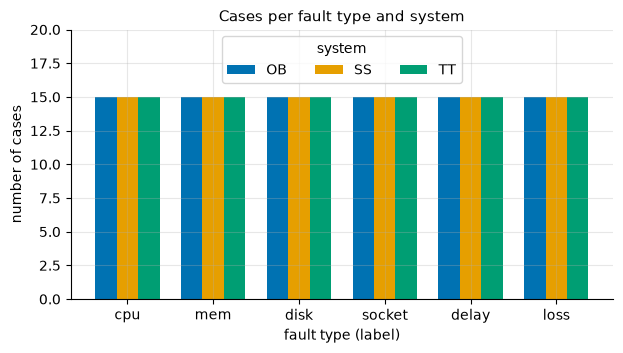

In [6]:
per_fault = balance.drop(index="all systems").drop(columns="all faults")
fig, ax = plt.subplots(figsize=(7, 3.5))
width = 0.25
x = np.arange(len(FAULTS))
for k, (system, row) in enumerate(per_fault.iterrows()):
    ax.bar(
        x + (k - 1) * width,
        row.to_numpy(),
        width,
        label=SYSTEM_NAMES[str(system)],
        color=SYSTEM_COLORS[str(system)],
    )
ax.set_xticks(x, list(FAULTS))
ax.set_ylim(0, 20)
ax.set_xlabel("fault type (label)")
ax.set_ylabel("number of cases")
ax.set_title("Cases per fault type and system")
ax.legend(title="system", ncol=3, loc="upper center")
plt.show()

The same counts as a chart. The balance comes from the injection protocol, not from real incident rates, so a deployed model would see an uneven mix of faults; we state this as a limitation.

### 2.2 Raw-data ranges and missing values

In [7]:
ranges = cases.groupby("system").agg(
    cases=("case_id", "size"),
    rows_min=("n_rows", "min"),
    rows_median=("n_rows", "median"),
    metric_cols_min=("n_metric_cols", "min"),
    metric_cols_median=("n_metric_cols", "median"),
    metric_cols_max=("n_metric_cols", "max"),
    nan_pct_median=("nan_pct", "median"),
    nan_pct_max=("nan_pct", "max"),
    inf_total=("inf_count", "sum"),
    inject_pos_min=("inject_pos", "min"),
    inject_pos_max=("inject_pos", "max"),
)
display(ranges.round(3).T)

system,re2ob,re2ss,re2tt
cases,90,90,90
rows_min,1186,1441,1441
rows_median,1441.0,1441.0,1441.0
metric_cols_min,59,67,318
metric_cols_median,64.0,69.0,334.5
metric_cols_max,67,75,348
nan_pct_median,0.004,0.018,0.31
nan_pct_max,17.321,11.135,4.244
inf_total,0,0,0
inject_pos_min,0.5,0.5,0.5


Raw-file sizes by system (`n_rows` counts every row in the file, including untimed ones; `nan_pct` is the share of missing metric cells in the raw file). The systems differ most in width: about 64 metric columns for OB, 69 for SS and 335 for TT after cleaning. Missing values are rare except in TT (median 0.31% of cells) and in the two OB cases with untimed rows (up to 17.3%).

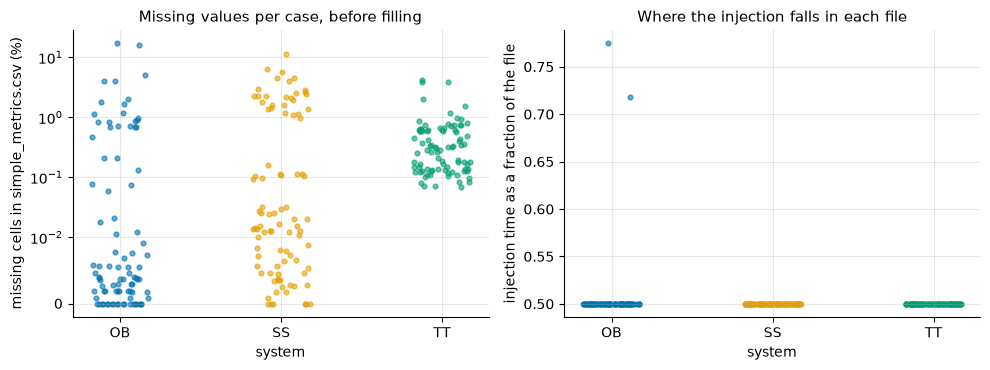

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
rng = np.random.default_rng(SEED)
for k, system in enumerate(SYSTEM_NAMES):
    sub = cases[cases["system"] == system]
    jitter = rng.uniform(-0.18, 0.18, len(sub))
    axes[0].scatter(
        k + jitter,
        sub["nan_pct"],
        s=12,
        alpha=0.6,
        color=SYSTEM_COLORS[system],
    )
    axes[1].scatter(
        k + jitter,
        sub["inject_pos"],
        s=12,
        alpha=0.6,
        color=SYSTEM_COLORS[system],
    )
labels = [SYSTEM_NAMES[s] for s in SYSTEM_NAMES]
axes[0].set_yscale("symlog", linthresh=0.01)
axes[0].set_ylabel("missing cells in simple_metrics.csv (%)")
axes[0].set_title("Missing values per case, before filling")
axes[1].set_ylabel("injection time as a fraction of the file")
axes[1].set_title("Where the injection falls in each file")
for ax in axes:
    ax.set_xticks(range(3), labels)
    ax.set_xlabel("system")
plt.tight_layout()
plt.show()

Each dot is one case (the left axis is linear below 0.01% and logarithmic above). Most cases are missing under 1% of cells. SS splits into two groups, one near 0.01% and one at 1-10%, and TT cases all have some missing cells (about 0.07-4%). The injection sits at the midpoint (0.5) of every file except the two OB cases with untimed rows, so the detection windows always start inside the file.

### 2.3 Telemetry coverage and system size

In [9]:
cols_per_kind = pd.DataFrame(
    {
        kind: {
            system: median_range(
                inventory.loc[inventory["system"] == system, f"n_cols_{kind}"]
            )
            for system in SYSTEM_NAMES
        }
        for kind in KINDS
    }
)
display(short_names(cols_per_kind))

,cpu,mem,diskio,socket,latency,error,workload
OB,11 (11-11),11 (11-12),7 (4-9),11 (11-12),10 (10-10),3 (0-4),11 (10-13)
SS,15 (15-15),15 (15-16),8 (7-10),15 (15-16),7 (7-7),2 (0-6),7 (7-7)
TT,68 (68-68),68 (68-69),67 (67-67),68 (68-69),28 (22-28),8 (0-21),28 (22-28)


Metric columns per kind in `simple_metrics.csv`: median (min-max) over cases. The kinds are far from complete. Only 2-3 services export `error` in OB and SS (8 in TT), and `diskio` is missing for several services in OB and SS but present for almost every service in TT.

In [10]:
at_delay_0 = features.loc[features["delay_s"] == 0]
services_per_kind = pd.DataFrame(
    {
        kind: {
            system: int(
                med(at_delay_0, at_delay_0["system"] == system, f"n_services_{kind}")
            )
            for system in SYSTEM_NAMES
        }
        for kind in KINDS
    }
)
display(short_names(services_per_kind))

,cpu,mem,diskio,socket,latency,error,workload
OB,11,11,7,11,10,3,11
SS,11,11,7,11,7,2,7
TT,68,68,67,68,28,8,28


Services per kind as the features count them, after a service and its `-db` are merged into one. The systems have 11 (OB), 11 (SS) and 68 (TT) services. SS has 15 CPU columns but 11 services, because 4 databases are merged with their services. TT is about 6 times larger than the other two, which is why count-type features (`*_abssum`, `*_n_gt3`) can't be compared directly across systems.

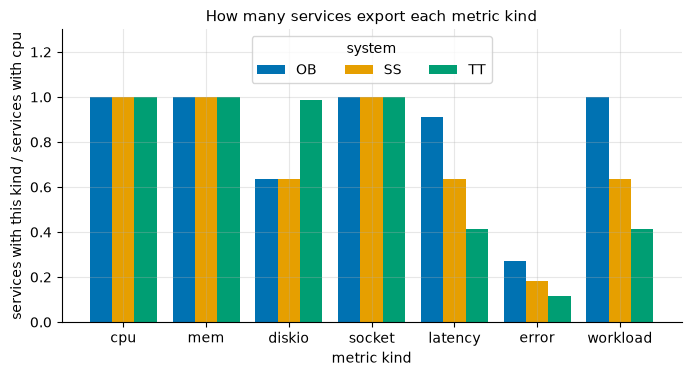

In [11]:
coverage = services_per_kind.div(services_per_kind["cpu"], axis=0)
fig, ax = plt.subplots(figsize=(8, 3.8))
width = 0.27
x = np.arange(len(KINDS))
for k, (system, row) in enumerate(coverage.iterrows()):
    ax.bar(
        x + (k - 1) * width,
        row.to_numpy(),
        width,
        label=SYSTEM_NAMES[str(system)],
        color=SYSTEM_COLORS[str(system)],
    )
ax.set_xticks(x, list(KINDS))
ax.set_ylim(0, 1.3)
ax.set_xlabel("metric kind")
ax.set_ylabel("services with this kind / services with cpu")
ax.set_title("How many services export each metric kind")
ax.legend(title="system", ncol=3, loc="upper center")
plt.show()

Coverage as a share of the services that export `cpu`. `cpu`, `mem` and `socket` cover every service. `diskio` covers 64% of OB and SS services but 99% of TT. Latency and workload cover most OB services (91% and 100%) but fewer in SS (64%) and TT (41%), and `error` covers only 12-27% of services in every system.

In [12]:
disk = at_delay_0.loc[at_delay_0["fault"] == "disk"]
other = at_delay_0.loc[at_delay_0["fault"] != "disk"]


# Share of rows of one system where diskio clearly shifted (z above 3).
def share_shifted(frame: pd.DataFrame, system: str) -> float:
    sub = frame.loc[frame["system"] == system, "diskio_n_gt3"]
    return float((sub.to_numpy(dtype=float) > 0).mean())


# Median of a column over the rows of one system.
def median_of(frame: pd.DataFrame, system: str, column: str) -> float:
    sub = frame.loc[frame["system"] == system, column]
    return float(np.median(sub.to_numpy(dtype=float)))


gap = pd.DataFrame(
    {
        system: {
            "disk cases": int((disk["system"] == system).sum()),
            "services with diskio": median_of(disk, system, "n_services_diskio"),
            "services with cpu": median_of(disk, system, "n_services_cpu"),
            "diskio clearly shifted, disk faults": share_shifted(disk, system),
            "diskio clearly shifted, other faults": share_shifted(other, system),
            "median mem_max, disk faults": median_of(disk, system, "mem_max"),
            "median cpu_max, disk faults": median_of(disk, system, "cpu_max"),
        }
        for system in SYSTEM_NAMES
    }
).T
display(short_names(gap).round(2))

,disk cases,services with diskio,services with cpu,"diskio clearly shifted, disk faults","diskio clearly shifted, other faults","median mem_max, disk faults","median cpu_max, disk faults"
OB,15.0,6.0,11.0,0.27,0.03,6.30,4.67
SS,15.0,7.0,11.0,0.07,0.05,8.36,5.95
TT,15.0,67.0,68.0,1.00,0.23,4.71,3.32


**The disk telemetry gap.** For disk faults (delay 0), `diskio` clearly shifts (by more than 3 in z) in only 27% of OB cases and 7% of SS cases, against 100% of TT cases, while the memory shift (`mem_max`) is large everywhere (4.7 to 8.4). In OB and SS the injected disk stress mostly shows up as memory and CPU (page cache), not as disk I/O, so a disk fault there looks like a memory fault. The go/no-go spike on the raw files found that only 2 of the 5 disk-fault services in OB export `diskio` at all (spec §5.3); the committed tables only count columns per case, so we don't recompute that figure here.

### 2.4 Feature ranges

,min,25%,50%,75%,max
cpu_max,-3.53,1.15,3.45,5.24,9.08
mem_max,-2.76,1.02,2.71,5.22,9.53
diskio_max,-2.07,-0.16,0.53,1.09,13.76
socket_max,-4.42,0.00,1.36,2.17,6.78
latency_max,-4.61,3.82,6.02,7.55,11.33
error_max,-0.62,0.00,0.00,0.00,4.64
workload_max,-3.47,-0.93,-0.60,0.45,2.36


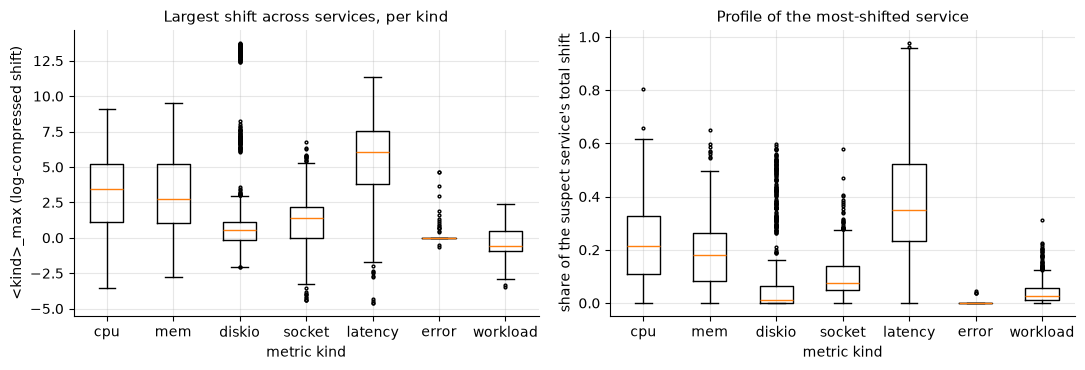

In [13]:
max_cols = [f"{k}_max" for k in KINDS]
share_cols = [f"top_{k}_share" for k in KINDS]
display(features[max_cols].describe().T[["min", "25%", "50%", "75%", "max"]].round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].boxplot(
    [features[c] for c in max_cols], tick_labels=list(KINDS), flierprops={"ms": 2}
)
axes[0].set_xlabel("metric kind")
axes[0].set_ylabel("<kind>_max (log-compressed shift)")
axes[0].set_title("Largest shift across services, per kind")
axes[1].boxplot(
    [features[c] for c in share_cols], tick_labels=list(KINDS), flierprops={"ms": 2}
)
axes[1].set_xlabel("metric kind")
axes[1].set_ylabel("share of the suspect service's total shift")
axes[1].set_title("Profile of the most-shifted service")
plt.tight_layout()
plt.show()

Shift features are log-compressed z-scores, so they stay in a narrow range (about -5 to +14 here) instead of spanning orders of magnitude. A clear shift (z above 3) is 1.39 on this scale. `latency_max` is typically the largest (median 6.0), `cpu_max` and `mem_max` are next (3.5 and 2.7), and `workload_max` is mostly negative (median -0.6). `error_max` is exactly 0 in 99% of rows because few services export `error` and it almost never shifts. The shares (right) are fractions between 0 and 1 that sum to 1 across kinds for the suspect service.

### 2.5 Fault signatures

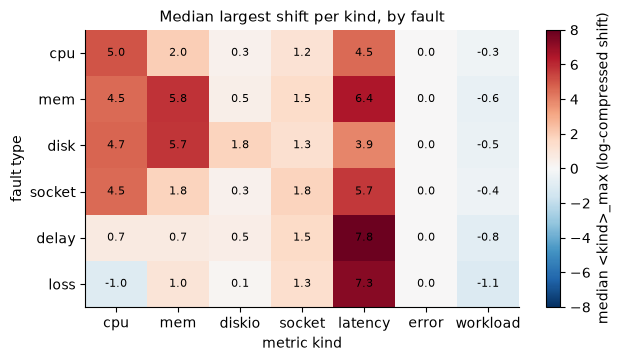

In [14]:
signature = pd.DataFrame(
    {
        kind: {
            fault: med(features, features["fault"] == fault, f"{kind}_max")
            for fault in FAULTS
        }
        for kind in KINDS
    }
)
reach = pd.DataFrame(
    {
        kind: {
            fault: share_pos(features, features["fault"] == fault, f"{kind}_n_gt3")
            for fault in FAULTS
        }
        for kind in KINDS
    }
)


def heatmap(ax, data, title, cmap, vmin, vmax, fmt):
    image = ax.imshow(data.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(data.shape[1]), list(data.columns))
    ax.set_yticks(range(data.shape[0]), list(data.index))
    for i, j in itertools.product(range(data.shape[0]), range(data.shape[1])):
        ax.text(j, i, format(data.iat[i, j], fmt), ha="center", va="center", fontsize=8)
    ax.grid(False)
    ax.set_title(title)
    ax.set_xlabel("metric kind")
    ax.set_ylabel("fault type")
    return image


fig, ax = plt.subplots(figsize=(7, 3.6))
img = heatmap(
    ax,
    signature,
    "Median largest shift per kind, by fault",
    "RdBu_r",
    -8,
    8,
    ".1f",
)
fig.colorbar(img, ax=ax, label="median <kind>_max (log-compressed shift)")
plt.show()

Median of each `<kind>_max` by fault, over all 1,350 rows (red is a rise, blue a drop). Reading the rows:

- **cpu:** CPU rises most (5.0), memory barely (2.0), latency follows (4.5).
- **mem:** memory (5.8) and CPU (4.5) both rise, and latency is high (6.4).
- **disk:** looks like `mem`: memory 5.7, CPU 4.7. Disk I/O is the only extra sign (1.8), and it is weak (see 2.3).
- **socket:** the socket count rises only modestly (1.8), CPU (4.5) and latency (5.7) rise more, and memory stays low.
- **delay:** latency is the largest (7.8) while CPU and memory hardly move (0.7).
- **loss:** latency also rises (7.3), but CPU drops (-1.0) and workload falls most (-1.1).

Two pairs look hard to separate from these medians alone: `mem` vs `disk`, and `delay` vs `loss`. We check this against the model's confusion matrix in the modeling section.

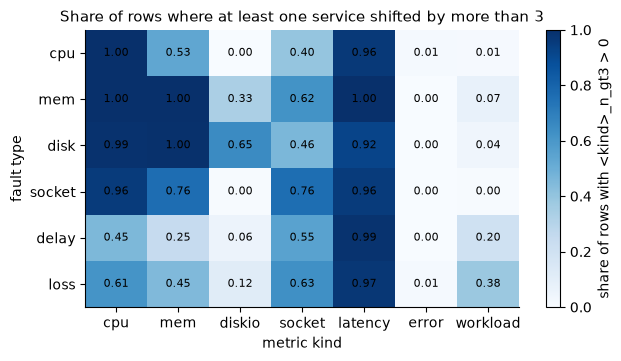

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
img = heatmap(
    ax,
    reach,
    "Share of rows where at least one service shifted by more than 3",
    "Blues",
    0,
    1,
    ".2f",
)
fig.colorbar(img, ax=ax, label="share of rows with <kind>_n_gt3 > 0")
plt.show()

How often each kind shows a clear shift for each fault. Latency shifts in at least 92% of rows for every fault, so it says "something is wrong" but not what. CPU separates `cpu`, `mem`, `disk` and `socket` (96-100%) from `delay` (45%) and `loss` (61%). Memory separates `mem` and `disk` (100%) from `cpu` (53%), `socket` (76%) and the network faults (25-45%). `error` almost never shifts (at most 1%).

In [16]:
by_delay = pd.DataFrame(
    {
        kind: {
            delay: float(
                np.median(
                    np.abs(
                        features.loc[
                            features["delay_s"] == delay, f"{kind}_max"
                        ].to_numpy(dtype=float)
                    )
                )
            )
            for delay in DELAYS_S
        }
        for kind in KINDS
    }
)
display(by_delay.round(2))

,cpu,mem,diskio,socket,latency,error,workload
0,4.03,2.94,0.59,2.47,6.51,0.0,0.78
30,4.03,2.69,0.75,1.65,6.29,0.0,0.77
60,3.65,2.76,0.71,1.40,5.97,0.0,0.78
90,3.34,2.80,0.71,1.32,5.70,0.0,0.75
120,2.97,2.70,0.69,1.29,5.34,0.0,0.76


Median size of `<kind>_max` by detection delay. The shifts get smaller as the delay grows (for example `cpu` from 4.0 at 0 s to 3.0 at 120 s, and `latency` from 6.5 to 5.3), because the baseline then already contains some fault data. The shift is still clear at 120 s. This is expected and matches a real alert that fires late.

### 2.6 One raw case

most-shifted metrics: ['productcatalogservice_latency-90', 'recommendationservice_latency-90', 'productcatalogservice_cpu', 'productcatalogservice_socket']


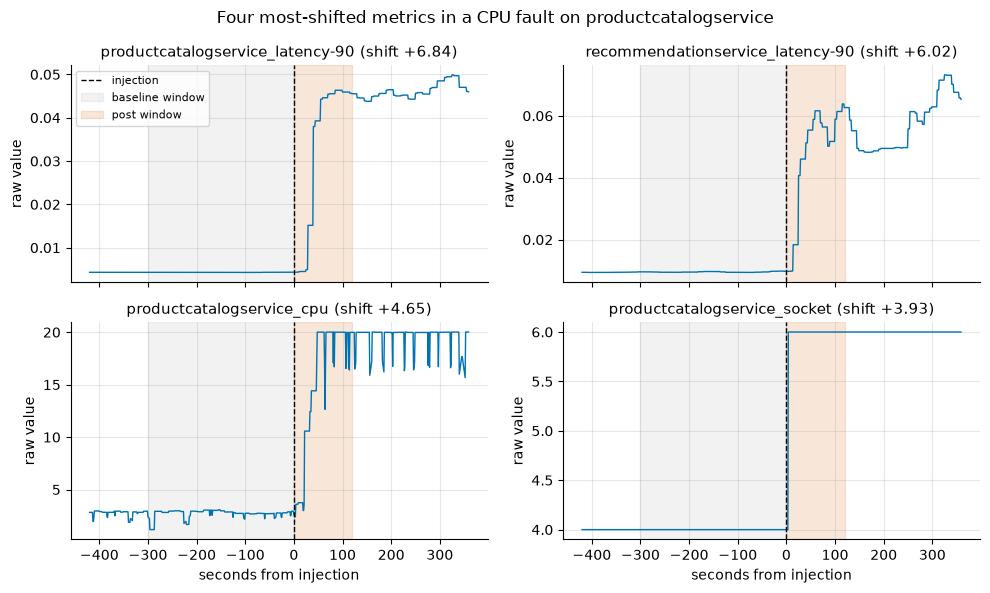

In [17]:
inject_time = int((FIXTURE / "inject_time.txt").read_text().strip())
times = clean["time"]
baseline = clean.loc[(times >= inject_time - BASELINE_S) & (times < inject_time)]
post = clean.loc[(times >= inject_time) & (times < inject_time + POST_S)]
shift = shift_scores(baseline.drop(columns="time"), post.drop(columns="time"))
top4 = [str(c) for c in shift.abs().sort_values(ascending=False).head(4).index]
print("most-shifted metrics:", top4)

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, column in zip(axes.ravel(), top4, strict=True):
    ax.plot(clean["time"] - inject_time, clean[column], lw=1, color="#0072B2")
    ax.axvline(0, color="black", ls="--", lw=1, label="injection")
    ax.axvspan(-BASELINE_S, 0, color="#999999", alpha=0.12, label="baseline window")
    ax.axvspan(0, POST_S, color="#D55E00", alpha=0.15, label="post window")
    ax.set_title(f"{column} (shift {shift[column]:+.2f})")
    ax.set_ylabel("raw value")
for ax in axes[1]:
    ax.set_xlabel("seconds from injection")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Four most-shifted metrics in a CPU fault on productcatalogservice")
plt.tight_layout()
plt.show()

One real case: a CPU fault on `productcatalogservice` (RE2-OB). Right after the dashed injection line, the p90 latency of the injected service jumps from about 0.004 to 0.045 and the latency of `recommendationservice` also rises. The injected service's CPU climbs from about 3 to 20 and stays there, and its socket count steps from 4 to 6. The number in each title is the shift: the median of the orange post window against the median of the gray baseline window, in units of baseline noise, log-compressed. The raw values sit on very different scales (0.004, 3, 4), which is why the features use shifts and not raw values.

### 2.7 Why the scale floor and log compression matter

In [18]:
base_only = baseline.drop(columns="time")
post_only = post.drop(columns="time")
z_plain = shift_scores(base_only, post_only, z_floor=0, log_z=False)
z_default = shift_scores(base_only, post_only)
injected = "productcatalogservice_cpu"
compare = pd.DataFrame(
    {
        "baseline median": base_only.median(),
        "plain z": z_plain,
        "default shift": z_default,
        "rank (plain)": z_plain.abs().rank(ascending=False).astype(int),
        "rank (default)": z_default.abs().rank(ascending=False).astype(int),
    }
)
display(compare.sort_values("rank (plain)").head(8).round(2))
print(
    f"{injected}: rank {compare.loc[injected, 'rank (plain)']} with plain z, ", end=""
)
print(f"rank {compare.loc[injected, 'rank (default)']} with the default shift")

,baseline median,plain z,default shift,rank (plain),rank (default)
productcatalogservice_latency-90,0.00,1000.00,6.84,1,1
recommendationservice_latency-90,0.01,408.95,6.02,2,2
productcatalogservice_cpu,2.82,103.56,4.65,3,3
productcatalogservice_mem,10174464.00,31.63,3.49,4,5
recommendationservice_mem,46358528.00,-2.70,-0.10,5,36
frontend_latency-90,0.62,-2.38,-1.22,6,6
emailservice_workload,0.73,2.35,1.21,7,7
adservice_latency-90,0.00,2.11,0.34,8,26


productcatalogservice_cpu: rank 3 with plain z, rank 3 with the default shift


The same fixture case scored two ways: plain z (no scale floor, no log compression; clipped at 1000) and the default shift. Plain z reaches 1000 for a latency column whose baseline median is about 0, and 104 for the injected CPU column, so one near-constant metric can dominate any sum or maximum. The default shift puts the same columns at 6.8 and 4.6. The injected CPU column ranks third either way here, but near-constant columns such as `recommendationservice_mem` (rank 5 with plain z, rank 36 with the default) and `adservice_latency-90` (8 and 26) no longer crowd the top. In the go/no-go spike, this change took logistic regression on OB from 0.54 to 0.85 macro F1 (spec §5.3); we don't re-measure it here because this notebook trains no models.

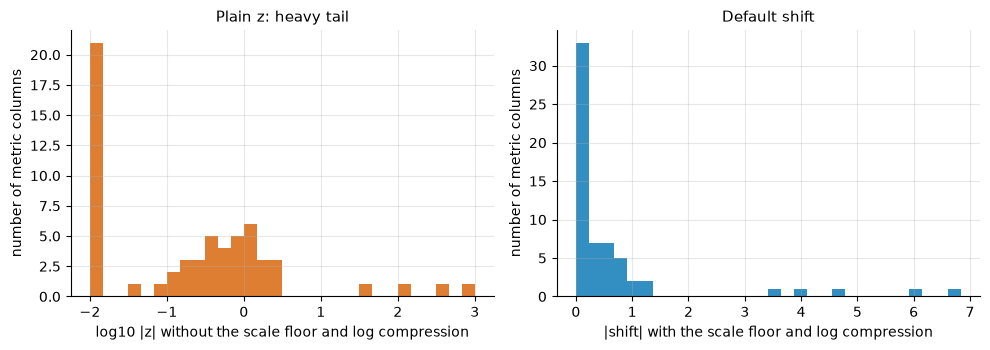

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(
    np.log10(z_plain.abs().clip(lower=1e-2)), bins=30, color="#D55E00", alpha=0.8
)
axes[0].set_xlabel("log10 |z| without the scale floor and log compression")
axes[0].set_ylabel("number of metric columns")
axes[0].set_title("Plain z: heavy tail")
axes[1].hist(z_default.abs(), bins=30, color="#0072B2", alpha=0.8)
axes[1].set_xlabel("|shift| with the scale floor and log compression")
axes[1].set_ylabel("number of metric columns")
axes[1].set_title("Default shift")
plt.tight_layout()
plt.show()

Distribution of the shift over all 61 metric columns of the case. Left: plain z on a log scale (values at or below 0.01 pile up in the first bin) has a tail out to 1000. Right: the default shift stays below 7, most columns are under 1.4, and only five columns have a shift above 3.

## 3. Feature importance (exploratory)

Mutual information (MI) measures how much a single feature tells us about the fault label, with no model involved. We estimate it with scikit-learn (`random_state=42`) on all 1,350 rows. This is a descriptive look, not an evaluation: the 5 rows of a case are near-duplicates, so the values are somewhat optimistic, and any feature selection that matters will happen inside grouped CV in the modeling section. The most MI one feature can carry is the label entropy, ln 6 = 1.79 nats.

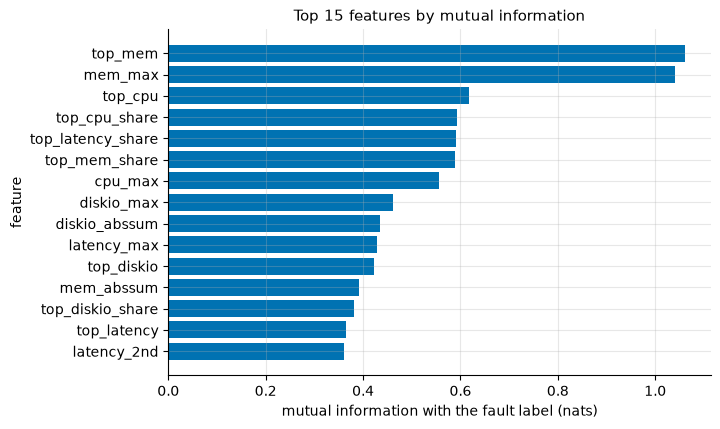

,mutual_info
top_mem,1.061
mem_max,1.041
top_cpu,0.618
top_cpu_share,0.592
top_latency_share,0.591
top_mem_share,0.588
cpu_max,0.556
diskio_max,0.461
diskio_abssum,0.435
latency_max,0.428


lowest five: {'top_error_share': 0.042, 'top_error': 0.027, 'error_2nd': 0.003, 'error_n_gt3': 0.001, 'error_abssum': 0.001}


In [20]:
mi = pd.Series(
    mutual_info_classif(features[FEATURE_NAMES], features["fault"], random_state=SEED),
    index=FEATURE_NAMES,
    name="mutual_info",
).sort_values(ascending=False)
top15 = mi.head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top15.index[::-1], top15.to_numpy()[::-1], color="#0072B2")
ax.set_xlabel("mutual information with the fault label (nats)")
ax.set_ylabel("feature")
ax.set_title("Top 15 features by mutual information")
plt.show()
display(mi.head(15).round(3).to_frame())
print("lowest five:", mi.tail(5).round(3).to_dict())

The two memory features carry the most information (`top_mem` 1.06 and `mem_max` 1.04 nats, well over half of the 1.79 maximum), consistent with the heatmap: memory splits `mem` and `disk` from the other four faults. Next come CPU and the profile shares (0.56-0.62). The `diskio` features rank 8th, 9th, 11th and 13th, which is probably driven by TT, where disk I/O shifts strongly for disk faults (2.3); 3.1 checks this by system. The five lowest features are all `error` features (at most 0.04), so they carry almost no information.

In [21]:
kind_of_feature = {n: n.removeprefix("top_").split("_")[0] for n in FEATURE_NAMES}
by_kind = pd.Series(
    {
        kind: float(
            np.mean([mi[n] for n in FEATURE_NAMES if kind_of_feature[n] == kind])
        )
        for kind in KINDS
    },
    name="mean mutual information",
)
display(by_kind.round(3).to_frame())

,mean mutual information
cpu,0.399
mem,0.600
diskio,0.386
socket,0.199
latency,0.336
error,0.020
workload,0.158


Mean MI per metric kind. Memory is the most informative kind (0.60), then CPU (0.40), `diskio` (0.39) and latency (0.34). Socket (0.20) and workload (0.16) say less, and `error` (0.02) almost nothing.

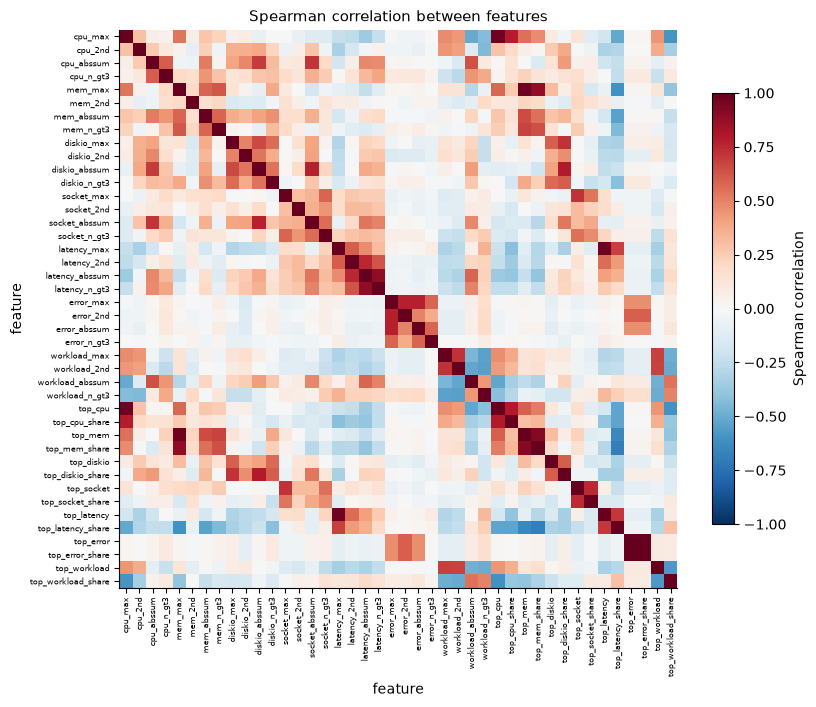

In [22]:
corr = pd.DataFrame(features[FEATURE_NAMES]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90, fontsize=6)
ax.set_yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, fontsize=6)
ax.grid(False)
ax.set_title("Spearman correlation between features")
ax.set_xlabel("feature")
ax.set_ylabel("feature")
fig.colorbar(image, ax=ax, shrink=0.7, label="Spearman correlation")
plt.show()

Spearman correlation between the 42 model features. Most pairs are only weakly correlated. The visible blocks are within a kind (for example the four `diskio` aggregates, or `latency_abssum` with `latency_n_gt3`) and between a kind's `_max` and the suspect service's `top_` value. The `top_*_share` features are negatively correlated with each other, because the shares of one service sum to 1.

In [23]:
pairs = pd.DataFrame(
    [
        (a, b, corr.loc[a, b])
        for a, b in itertools.combinations(FEATURE_NAMES, 2)
        if abs(corr.loc[a, b]) >= 0.9
    ],
    columns=["feature a", "feature b", "spearman"],
).sort_values("spearman", key=abs, ascending=False)
print(f"{len(pairs)} feature pairs with |rho| >= 0.9")
display(pairs.round(2).reset_index(drop=True))

5 feature pairs with |rho| >= 0.9


,feature a,feature b,spearman
0,top_error,top_error_share,1.00
1,cpu_max,top_cpu,0.98
2,latency_max,top_latency,0.98
3,mem_max,top_mem,0.97
4,top_mem,top_mem_share,0.92


Only 5 of the 861 feature pairs have |rho| of 0.9 or more. Three are `<kind>_max` with the suspect service's `top_<kind>` (CPU, memory, latency): the most-shifted service is usually the one with the largest shift. One is `top_mem` with `top_mem_share`, and one is the two `error` features, which are almost always 0. The features aren't heavily redundant. Tree models don't mind correlated inputs, but the logistic regression coefficients in the modeling section will split credit between these pairs.

### 3.1 Per-system differences

In [24]:
mi_by_system = pd.DataFrame(
    {
        SYSTEM_NAMES[system]: pd.Series(
            mutual_info_classif(
                features.loc[features["system"] == system, FEATURE_NAMES],
                features.loc[features["system"] == system, "fault"],
                random_state=SEED,
            ),
            index=FEATURE_NAMES,
        )
        for system in SYSTEM_NAMES
    }
)
top5 = pd.DataFrame(
    {
        name: [f"{f} ({mi_by_system.at[f, name]:.2f})" for f in col.nlargest(5).index]
        for name, col in mi_by_system.items()
    },
    index=[f"#{i}" for i in range(1, 6)],
)
display(top5)
print(
    "Spearman correlation of the MI ranking between systems:\n",
    mi_by_system.corr(method="spearman").round(2),
)

,OB,SS,TT
#1,top_mem (1.15),top_mem (1.25),top_mem (1.43)
#2,mem_max (1.14),mem_max (1.16),mem_max (1.37)
#3,latency_max (0.75),top_mem_share (0.94),top_mem_share (0.92)
#4,top_latency_share (0.75),top_cpu_share (0.89),top_diskio_share (0.92)
#5,top_latency (0.69),top_latency_share (0.84),top_cpu_share (0.90)


Spearman correlation of the MI ranking between systems:
       OB    SS    TT
OB  1.00  0.82  0.71
SS  0.82  1.00  0.60
TT  0.71  0.60  1.00


Top 5 features by MI within each system (MI in parentheses), and how similar the full rankings are. Memory is first or second in every system. After that the systems differ: OB's top 5 are memory and latency features, while SS and TT's are memory plus the suspect service's profile shares (TT includes `top_diskio_share`, where disk telemetry is complete). The rankings agree most for OB and SS (0.82) and least for SS and TT (0.60).

,cpu_max,mem_max,latency_max,cpu_abssum
system,,,,
OB,4.74,2.68,6.37,9.87
SS,6.08,4.20,5.45,10.81
TT,4.03,1.02,3.64,32.28


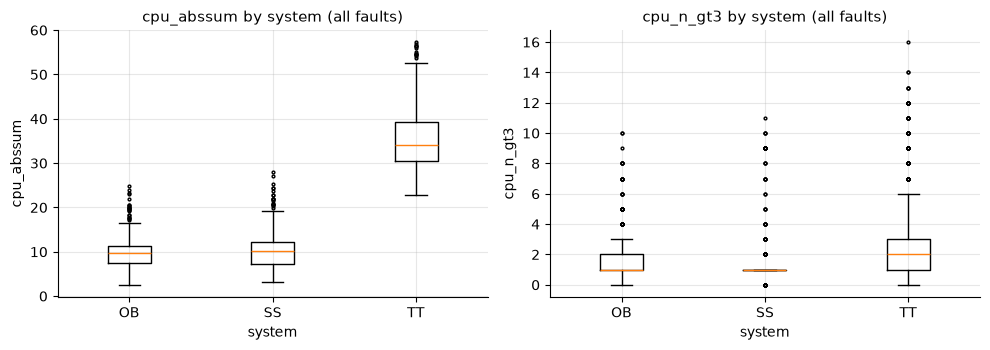

In [25]:
cpu_cases = features[features["fault"] == "cpu"]
display(
    cpu_cases.groupby("system")[["cpu_max", "mem_max", "latency_max", "cpu_abssum"]]
    .median()
    .rename(index=SYSTEM_NAMES)
    .round(2)
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, column in zip(axes, ["cpu_abssum", "cpu_n_gt3"], strict=True):
    ax.boxplot(
        [features.loc[features["system"] == s, column] for s in SYSTEM_NAMES],
        tick_labels=list(SYSTEM_NAMES.values()),
        flierprops={"ms": 2},
    )
    ax.set_xlabel("system")
    ax.set_ylabel(column)
    ax.set_title(f"{column} by system (all faults)")
plt.tight_layout()
plt.show()

The same fault looks different in each system. For `cpu` faults the median `cpu_max` is 4.7 (OB), 6.1 (SS) and 4.0 (TT), and the memory shift is 2.7, 4.2 and 1.0. The count-type features also grow with system size: the median `cpu_abssum` is about 10 in OB and SS and about 34 in TT, which has 68 services against 11. A model trained on two systems may therefore not transfer to the third. The go/no-go spike measured this gap (spec §5.3); plan line 7 re-measures it with leave-one-system-out and tests `--norm-counts`, which replaces the sum and count with a per-service mean and fraction.

## 4. Summary

What this EDA tells us, and what it hands to the modeling section:

- **Data:** 270 cases (45 per fault, 15 per fault per system) give 1,350 rows of 42 features. No case is skipped. The quirks are handled in `faulttrack.data`.
- **Signatures:** CPU, memory and latency shifts separate most faults. The two pairs that look hardest to tell apart are `mem` vs `disk` and `delay` vs `loss`; the confusion matrix will show whether that holds.
- **Telemetry gaps:** `diskio` is missing for about a third of the services in OB and SS, so disk faults there look like memory faults. `error` almost never shifts and carries almost no information.
- **Scaling:** the scale floor and log compression keep near-constant metrics from dominating (2.7).
- **Importance:** memory features have the most mutual information, and few features are redundant.
- **Systems differ** in size (11, 11 and 68 services) and in the size of the same fault's shift, which motivates the unseen-system analysis in plan line 7.
- **Next (plan line 6):** compare the dummy, rule, logistic regression, decision tree, random forest and XGBoost models with CV grouped by `case_id` (5 windows per case), report macro F1 as mean ± std (min/max) across folds, and tune with the same grouped folds.